# PCS5917 — IA Adversarial
## Aula 3 — Detecção de Áudio Falso
**Aluno:** Caio Vinícius Ribeiro da Silva\
**Disciplina:** PCS5917 – IA Adversarial\
**Período:** 3º período de 2026\
**Instituição:** Universidade de São Paulo – Escola Politécnica\
**Professor:** Victor Takashi Hayashi\ 
**Data da atividade:** 07/10/2026  


Usei uma amostra balanceada do ASVspoof 5 para extrair características, analisar os áudios e treinar um classificador. Fiz tudo localmente, substituindo o Drive e o Colab.


### Ambiente local

```bash
python3 -m venv .venv-aula03
.venv-aula03/bin/python -m pip install -r notebooks/requirements-aula03.txt
.venv-aula03/bin/python -m ipykernel install --prefix .venv-aula03 --name pcs5917-aula03 --display-name "Python (PCS5917 Aula 3)"
JUPYTER_PATH="$PWD/.venv-aula03/share/jupyter" .venv-aula03/bin/python -m jupyterlab notebooks/aula_03_deteccao_audio_falso.ipynb
```

Use o kernel **Python (PCS5917 Aula 3)**. Os 2.000 áudios já baixados ficam em `dados/aula-03/dataset/`; nesta atividade usei 200. Os dados e o ambiente virtual ficam fora do Git.


In [1]:
import sys
import importlib.util

DEPENDENCIAS = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib", "librosa": "librosa", "soundfile": "soundfile", "sklearn": "scikit-learn", "kagglehub": "kagglehub"}
ausentes = [pacote for modulo, pacote in DEPENDENCIAS.items() if importlib.util.find_spec(modulo) is None]
print("Interpretador do kernel:", sys.executable)
if ausentes:
    raise RuntimeError(f"Dependências ausentes: {ausentes}. Instale notebooks/requirements-aula03.txt no ambiente virtual e selecione o kernel correspondente.")

Interpretador do kernel: /home/vader/Sync/Academico/04-PPgSI/02-mestrado/05-code/PCS5917 - IA Adversarial/portfolio-pcs5917/.venv-aula03/bin/python


In [2]:
from pathlib import Path

def localizar_raiz_projeto(inicio=None):
    inicio = Path(inicio or Path.cwd()).resolve()
    for candidato in (inicio, *inicio.parents):
        if (candidato / "notebooks/aula_03_deteccao_audio_falso.ipynb").is_file() and (candidato / "README.md").is_file():
            return candidato
    raise FileNotFoundError("Abra o notebook a partir da raiz do projeto ou da pasta notebooks/.")

RAIZ_PROJETO = localizar_raiz_projeto()
BASE = RAIZ_PROJETO / "dados/aula-03"
DATASET_DIR = BASE / "dataset"  # Pode apontar para outra pasta local já descompactada.
SUBCONJUNTO_DIR = BASE / "subconjunto"
RESULTADOS_DIR = RAIZ_PROJETO / "resultados/aula-03"
FIGURAS_DIR = RAIZ_PROJETO / "images/aula-03"
for pasta in (BASE, RESULTADOS_DIR, FIGURAS_DIR):
    pasta.mkdir(parents=True, exist_ok=True)
print("Raiz do projeto:", RAIZ_PROJETO)
print("Pasta de dados locais:", BASE)

Raiz do projeto: /home/vader/Sync/Academico/04-PPgSI/02-mestrado/05-code/PCS5917 - IA Adversarial/portfolio-pcs5917
Pasta de dados locais: /home/vader/Sync/Academico/04-PPgSI/02-mestrado/05-code/PCS5917 - IA Adversarial/portfolio-pcs5917/dados/aula-03


In [3]:
import json, hashlib, shutil, sys
from datetime import datetime, timezone
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import soundfile as sf
from IPython.display import display
from sklearn.model_selection import StratifiedGroupKFold

SEMENTE = 5917
N_POR_CLASSE = 100  # 200 áudios na atividade.
SR = 16000
MAX_SEGUNDOS = 6.0  # Usa os primeiros 6 s; não preenche áudios curtos com silêncio.
N_FFT = 512
HOP_LENGTH = 160
N_MFCC = 20
N_FOLDS = 5
DOWNLOAD_KAGGLE = False  # True apenas se quiser baixar o dataset integral nesta sessão.
DATASET_KAGGLE = "ulianazb/asvspoof-2024"
if DOWNLOAD_KAGGLE:
    import kagglehub
    # Se o acesso exigir autenticação, use kagglehub.login(); não cole tokens no notebook.
    DATASET_DIR = Path(kagglehub.dataset_download(DATASET_KAGGLE))
    print("Download/cache do Kaggle:", DATASET_DIR)

config = {
    "ambiente": "local", "dataset": DATASET_KAGGLE, "semente": SEMENTE, "n_por_classe": N_POR_CLASSE,
    "sr": SR, "max_segundos": MAX_SEGUNDOS, "n_fft": N_FFT,
    "hop_length": HOP_LENGTH, "n_mfcc": N_MFCC, "n_folds": N_FOLDS,
    "utc": datetime.now(timezone.utc).isoformat(), "python": sys.version,
    "pacotes": {p: version(p) for p in ("librosa", "soundfile", "scikit-learn", "pandas", "numpy", "matplotlib", "kagglehub")},
}
(RESULTADOS_DIR / "configuracao.json").write_text(json.dumps(config, indent=2), encoding="utf-8")

522

### 1. Dataset e rótulos
Usei os áudios de treino do ASVspoof 5 disponíveis no Kaggle e o protocolo filtrado dos arquivos baixados. Os rótulos são `0 = legítimo` e `1 = falso`.


In [4]:
assert DATASET_DIR.exists(), f"Coloque o dataset descompactado em {DATASET_DIR}, ou ative DOWNLOAD_KAGGLE."
EXTENSOES = {".wav", ".flac", ".ogg"}
audios_disponiveis = sorted(p for p in DATASET_DIR.rglob("*") if p.suffix.lower() in EXTENSOES)
assert audios_disponiveis, "Nenhum áudio encontrado: confira se os arquivos foram descompactados."
protocolos_disponiveis = sorted(p for p in DATASET_DIR.rglob("*") if p.suffix.lower() in {".txt", ".csv", ".tsv"})
print("Áudios disponíveis:", len(audios_disponiveis))
print("Exemplos:", [str(p.relative_to(DATASET_DIR)) for p in audios_disponiveis[:5]])
for p in protocolos_disponiveis[:20]:
    print("\nMETADADOS:", p.relative_to(DATASET_DIR))
    with p.open(encoding="utf-8", errors="replace") as f:
        for _ in range(3):
            linha = f.readline()
            if linha:
                print(linha.rstrip()[:500])

Áudios disponíveis: 2000
Exemplos: ['flac_T/T_0000000062.flac', 'flac_T/T_0000000189.flac', 'flac_T/T_0000000206.flac', 'flac_T/T_0000000224.flac', 'flac_T/T_0000000306.flac']

METADADOS: ASVspoof5.train.metadata.txt
T_4850 T_0000000000 F - A05 spoof
T_0858 T_0000000001 M - A07 spoof
T_4075 T_0000000002 M - A04 spoof

METADADOS: ASVspoof5.train.subconjunto.metadata.txt
T_2260 T_0000000062 F - bonafide bonafide
T_5389 T_0000000189 F - A08 spoof
T_5437 T_0000000206 F - A03 spoof


In [5]:
MODO_METADATA = "protocolo"  # "protocolo", "csv" ou "pastas"
PARTICAO_ORIGEM = "ASVspoof 5: treino, subconjunto Kaggle v2 (1.000 por classe)"
PROTOCOLO = DATASET_DIR / "ASVspoof5.train.subconjunto.metadata.txt"
# Protocolo baixado e conferido: locutor, áudio, gênero, -, ataque, rótulo.
# Índices abaixo correspondem às seis colunas do ASVspoof 5 desta cópia.
COLUNA_AUDIO = 1
COLUNA_ROTULO = 5
COLUNA_LOCUTOR = 0  # None se não houver identificação confiável de locutor.
COLUNA_ATAQUE = 4  # None se não houver.
PULAR_LINHAS = 0  # 1 se houver cabeçalho.
MANIFESTO_ENTRADA = DATASET_DIR / "manifesto.csv"
PASTA_LEGITIMO = DATASET_DIR / "bonafide"
PASTA_FALSO = DATASET_DIR / "spoof"

MAPA_ROTULOS = {"bonafide": 0, "bona-fide": 0, "bona_fide": 0,
    "genuine": 0, "real": 0, "legitimo": 0, "0": 0,
    "spoof": 1, "fake": 1, "falso": 1, "1": 1}

def normalizar_rotulo(valor):
    chave = str(valor).strip().lower()
    if chave not in MAPA_ROTULOS:
        raise ValueError(f"Rótulo desconhecido: {valor!r}; confira o protocolo antes de atualizar o mapa.")
    return MAPA_ROTULOS[chave]

def carregar_metadados():
    if MODO_METADATA == "csv":
        df = pd.read_csv(MANIFESTO_ENTRADA, dtype=str).fillna("")
        assert {"arquivo", "rotulo"}.issubset(df.columns)
        df["arquivo"] = df["arquivo"].map(lambda x: str((DATASET_DIR / x).resolve()))
    elif MODO_METADATA == "protocolo":
        assert PROTOCOLO.is_file(), "Configure PROTOCOLO com um arquivo existente."
        tabela = pd.read_csv(PROTOCOLO, sep=r"\s+", header=None, skiprows=PULAR_LINHAS, dtype=str).fillna("")
        # O índice exige IDs únicos na partição escolhida; ambiguidades não são resolvidas silenciosamente.
        por_id = {}
        for p in audios_disponiveis:
            por_id.setdefault(p.stem, []).append(p)
        caminhos = []
        for valor in tabela.iloc[:, COLUNA_AUDIO]:
            direto = DATASET_DIR / valor
            candidatos = [direto] if direto.is_file() else por_id.get(Path(valor).stem, [])
            if len(candidatos) != 1:
                raise ValueError(f"ID {valor}: {len(candidatos)} arquivos encontrados. Restrinja DATASET_DIR à partição correta ou use um manifesto CSV com caminhos explícitos.")
            caminhos.append(str(candidatos[0].resolve()))
        df = pd.DataFrame({"arquivo": caminhos, "rotulo": tabela.iloc[:, COLUNA_ROTULO]})
        df["locutor"] = tabela.iloc[:, COLUNA_LOCUTOR] if COLUNA_LOCUTOR is not None else ""
        df["ataque"] = tabela.iloc[:, COLUNA_ATAQUE] if COLUNA_ATAQUE is not None else ""
    elif MODO_METADATA == "pastas":
        registros = []
        for pasta, rotulo in [(PASTA_LEGITIMO, 0), (PASTA_FALSO, 1)]:
            assert pasta.is_dir(), f"Pasta ausente: {pasta}"
            registros.extend({"arquivo": str(p.resolve()), "rotulo": rotulo} for p in sorted(pasta.rglob("*")) if p.suffix.lower() in EXTENSOES)
        df = pd.DataFrame(registros)
    else:
        raise ValueError("MODO_METADATA inválido")
    for coluna in ("locutor", "ataque"):
        if coluna not in df:
            df[coluna] = ""
    df["rotulo"] = df["rotulo"].map(normalizar_rotulo)
    assert not df["arquivo"].duplicated().any(), "Arquivos repetidos no manifesto."
    assert df["arquivo"].map(lambda p: Path(p).is_file()).all(), "Há caminhos inexistentes."
    assert set(df["rotulo"]) == {0, 1}, "São necessárias as duas classes."
    return df.reset_index(drop=True)

assert PARTICAO_ORIGEM != "PREENCHER", "Registre a edição/partição confirmada antes de continuar."
metadados = carregar_metadados()
display(metadados.head())
display(metadados.groupby("rotulo").size().rename("quantidade"))
print("Locutores informados:", metadados["locutor"].replace("", np.nan).nunique())
config["particao_origem"] = PARTICAO_ORIGEM
config["modo_metadata"] = MODO_METADATA
config["colunas_protocolo"] = {"audio": COLUNA_AUDIO, "rotulo": COLUNA_ROTULO, "locutor": COLUNA_LOCUTOR, "ataque": COLUNA_ATAQUE, "pular_linhas": PULAR_LINHAS} if MODO_METADATA == "protocolo" else None
config["mapa_rotulos"] = MAPA_ROTULOS

,arquivo,rotulo,locutor,ataque
0,/home/vader/Sync/Academico/04-PPgSI/02-mestrad...,0,T_2260,bonafide
1,/home/vader/Sync/Academico/04-PPgSI/02-mestrad...,1,T_5389,A08
2,/home/vader/Sync/Academico/04-PPgSI/02-mestrad...,1,T_5437,A03
3,/home/vader/Sync/Academico/04-PPgSI/02-mestrad...,1,T_5104,A02
4,/home/vader/Sync/Academico/04-PPgSI/02-mestrad...,1,T_5451,A01


rotulo
0    1000
1    1000
Name: quantidade, dtype: int64

Locutores informados: 392


### 2–3. Subconjunto e notebook local
Selecionei 100 áudios de cada classe com semente 5917 e organizei as cópias em `dados/aula-03/subconjunto/`. A amostra ocupa 43,16 MiB. Usei este notebook local no lugar do Colab e do Drive.


In [6]:
def hash_arquivo(caminho):
    h = hashlib.sha256()
    with Path(caminho).open("rb") as f:
        for bloco in iter(lambda: f.read(1024 * 1024), b""):
            h.update(bloco)
    return h.hexdigest()

if MODO_METADATA == "protocolo":
    config["protocolo_sha256"] = hash_arquivo(PROTOCOLO)
elif MODO_METADATA == "csv":
    config["manifesto_entrada_sha256"] = hash_arquivo(MANIFESTO_ENTRADA)

assert metadados.groupby("rotulo").size().min() >= N_POR_CLASSE, "Reduza N_POR_CLASSE: não há áudios suficientes."
subconjunto = pd.concat([
    metadados[metadados.rotulo == classe].sample(N_POR_CLASSE, random_state=SEMENTE)
    for classe in (0, 1)
], ignore_index=True).sort_values("arquivo").reset_index(drop=True)
subconjunto["sha256"] = subconjunto.arquivo.map(hash_arquivo)
assert not subconjunto.sha256.duplicated().any(), "Áudios idênticos encontrados. Revise/remova duplicatas na origem e refaça a amostragem."
subconjunto["arquivo_origem"] = subconjunto["arquivo"]
for i, row in subconjunto.iterrows():
    pasta = SUBCONJUNTO_DIR / ("falso" if row.rotulo else "legitimo")
    pasta.mkdir(parents=True, exist_ok=True)
    destino = pasta / (row.sha256 + Path(row.arquivo).suffix.lower())
    if not destino.exists() or hash_arquivo(destino) != row.sha256:
        shutil.copy2(row.arquivo, destino)
    subconjunto.loc[i, "arquivo"] = str(destino)
# O manifesto define os arquivos ativos. Cópias de rodadas anteriores não entram por varredura da pasta.
subconjunto.to_csv(BASE / "manifesto_local.csv", index=False)
display(subconjunto.groupby("rotulo").size().rename("amostras"))
print("Subconjunto salvo localmente:", SUBCONJUNTO_DIR)

rotulo
0    100
1    100
Name: amostras, dtype: int64

Subconjunto salvo localmente: /home/vader/Sync/Academico/04-PPgSI/02-mestrado/05-code/PCS5917 - IA Adversarial/portfolio-pcs5917/dados/aula-03/subconjunto


### 4. Processamento
Usei librosa, alternativa permitida no enunciado. Processei até 6 segundos de cada áudio, em mono a 16 kHz, e extraí 52 características: médias e desvios de 20 MFCCs e de seis medidas de energia e espectro. Os 200 arquivos foram processados sem erros.


In [7]:
def extrair_features(caminho):
    info = sf.info(caminho)
    y, sr = librosa.load(caminho, sr=SR, mono=True, duration=MAX_SEGUNDOS)
    if len(y) < N_FFT or not np.isfinite(y).all():
        raise ValueError("Áudio curto demais ou com valores não finitos")
    espectro = np.abs(librosa.stft(y, n_fft=N_FFT, hop_length=HOP_LENGTH))
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=N_MFCC, n_fft=N_FFT, hop_length=HOP_LENGTH)
    sinais = {
        "rms": librosa.feature.rms(S=espectro, frame_length=N_FFT),
        "zcr": librosa.feature.zero_crossing_rate(y, frame_length=N_FFT, hop_length=HOP_LENGTH),
        "centroid": librosa.feature.spectral_centroid(S=espectro, sr=sr),
        "bandwidth": librosa.feature.spectral_bandwidth(S=espectro, sr=sr),
        "rolloff": librosa.feature.spectral_rolloff(S=espectro, sr=sr),
        "flatness": librosa.feature.spectral_flatness(S=espectro),
    }
    features = {}
    for i, valores in enumerate(mfcc, 1):
        features[f"mfcc_{i:02d}_mean"] = float(np.mean(valores))
        features[f"mfcc_{i:02d}_std"] = float(np.std(valores))
    for nome, valores in sinais.items():
        features[f"{nome}_mean"] = float(np.mean(valores))
        features[f"{nome}_std"] = float(np.std(valores))
    assert np.isfinite(list(features.values())).all(), "Features não finitas"
    return {**features, "duracao_original_s": info.duration, "duracao_processada_s": len(y) / sr,
            "sr_original": info.samplerate}

registros, erros = [], []
for i, row in subconjunto.iterrows():
    try:
        registros.append({**row.to_dict(), **extrair_features(row.arquivo)})
    except Exception as exc:
        erros.append({"sha256": row.sha256, "rotulo": row.rotulo, "erro": repr(exc)})
    if (i + 1) % 50 == 0:
        print(f"Processados {i + 1}/{len(subconjunto)}")
pd.DataFrame(erros, columns=["sha256", "rotulo", "erro"]).to_csv(RESULTADOS_DIR / "erros_extracao.csv", index=False)
assert not erros, "Há erros de extração: consulte erros_extracao.csv e corrija antes de treinar."
features = pd.DataFrame(registros)
features.to_csv(BASE / "features_locais.csv", index=False)
COLUNAS_MFCC = [c for c in features if c.startswith("mfcc_")]
COLUNAS_ESPECTRAIS = [f"{nome}_{stat}" for nome in ("rms", "zcr", "centroid", "bandwidth", "rolloff", "flatness") for stat in ("mean", "std")]
COLUNAS_FEATURES = COLUNAS_MFCC + COLUNAS_ESPECTRAIS
assert len(COLUNAS_FEATURES) == 52
print("Matriz de features:", features[COLUNAS_FEATURES].shape)

/home/vader/Sync/Academico/04-PPgSI/02-mestrado/05-code/PCS5917 - IA Adversarial/portfolio-pcs5917/.venv-aula03/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Processados 50/200


Processados 100/200


Processados 150/200


Processados 200/200
Matriz de features: (200, 52)


### Separação de treino e teste
Separei 159 áudios para treino e 41 para teste, sem repetir locutores entre os grupos. A análise exploratória usa apenas o treino.


In [8]:
def criar_folds(X, y, grupos, n_splits, seed):
    if pd.Series(grupos).nunique() < n_splits:
        raise ValueError(f"São necessários pelo menos {n_splits} grupos distintos.")
    folds = list(StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed).split(X, y, grupos))
    for treino, validacao in folds:
        if set(np.asarray(y)[treino]) != {0, 1} or set(np.asarray(y)[validacao]) != {0, 1}:
            raise ValueError("Um fold não contém as duas classes. Aumente a amostra/locutores ou reduza os folds; não ajuste a divisão pelo desempenho.")
        assert not set(np.asarray(grupos)[treino]) & set(np.asarray(grupos)[validacao])
    return folds

features["locutor"] = features["locutor"].fillna("").astype(str).str.strip()
TEM_LOCUTORES = features.locutor.ne("").all() and not features.locutor.isin(["-", "nan", "None"]).any()
TIPO_GRUPO = "locutor" if TEM_LOCUTORES else "sha256"
grupo = features[TIPO_GRUPO].to_numpy()
X = features[COLUNAS_FEATURES]
y = features.rotulo.astype(int).to_numpy()
idx_treino, idx_teste = criar_folds(X, y, grupo, N_FOLDS, SEMENTE)[0]
features["divisao"] = "treino"
features.loc[idx_teste, "divisao"] = "teste"
assert not set(features.iloc[idx_treino].sha256) & set(features.iloc[idx_teste].sha256)
treino = features.iloc[idx_treino].reset_index(drop=True)
teste = features.iloc[idx_teste].reset_index(drop=True)
config["agrupamento"] = TIPO_GRUPO
config["n_treino"] = len(treino)
config["n_teste"] = len(teste)
print("Agrupamento:", TIPO_GRUPO)
if not TEM_LOCUTORES:
    print("LIMITAÇÃO: metadados de locutor indisponíveis/incompletos; pode haver locutores compartilhados entre treino e teste.")
display(pd.crosstab(features.divisao, features.rotulo))

Agrupamento: locutor


rotulo,0,1
divisao,,
teste,20,21
treino,80,79


### 5. Análise exploratória
Comparei as características por classe e conferi a duração, a taxa de amostragem e os tipos de ataque.


duracao_original_s                                                \
                    count       mean       std     min      25%     50%   
rotulo                                                                    
0                    80.0  14.995750  2.733410  10.090  13.0375  14.975   
1                    79.0  11.646177  2.811661   5.824   9.3680  11.712   

                        duracao_processada_s                                  \
            75%     max                count      mean       std    min  25%   
rotulo                                                                         
0       17.0325  19.810                 80.0  6.000000  0.000000  6.000  6.0   
1       13.4560  18.816                 79.0  5.997772  0.019802  5.824  6.0   

                       
        50%  75%  max  
rotulo                 
0       6.0  6.0  6.0  
1       6.0  6.0  6.0

rotulo,0,1
sr_original,,
16000,80,79


rotulo,0,1
ataque,,
A01,0,13
A02,0,14
A03,0,13
A04,0,12
A05,0,7
A06,0,4
A07,0,8
A08,0,8
bonafide,80,0


mfcc_17_std    2.331129
mfcc_15_std    1.658234
mfcc_14_std    1.655578
mfcc_19_std    1.616475
mfcc_18_std    1.608954
mfcc_12_std    1.542339
mfcc_09_std    1.522001
mfcc_20_std    1.507887
mfcc_16_std    1.455642
mfcc_11_std    1.335576
dtype: float64

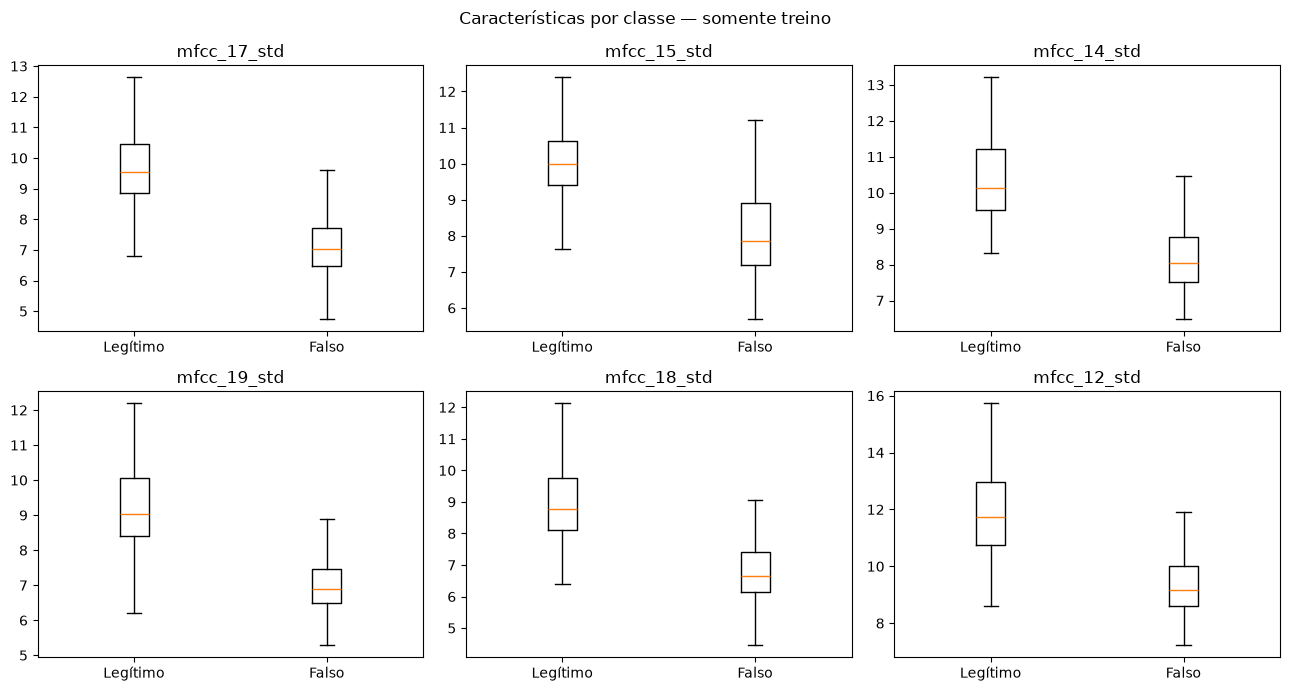

In [9]:
display(treino.groupby("rotulo")[["duracao_original_s", "duracao_processada_s"]].describe())
display(pd.crosstab(treino.sr_original, treino.rotulo))
if treino.ataque.fillna("").ne("").any():
    display(pd.crosstab(treino.ataque, treino.rotulo))
medias = treino.groupby("rotulo")[COLUNAS_FEATURES].mean()
variancias = treino.groupby("rotulo")[COLUNAS_FEATURES].var()
escala = np.sqrt((variancias.loc[0] + variancias.loc[1]) / 2).replace(0, np.nan)
ranking = ((medias.loc[1] - medias.loc[0]).abs() / escala).fillna(0).sort_values(ascending=False)
ranking.rename("diferenca_padronizada_abs").to_csv(RESULTADOS_DIR / "ranking_features_treino.csv")
display(ranking.head(10))
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, feature in zip(axes.ravel(), ranking.head(6).index):
    ax.boxplot([treino.loc[treino.rotulo == c, feature].values for c in (0, 1)], showfliers=False)
    ax.set_xticks([1, 2], ["Legítimo", "Falso"])
    ax.set_title(feature)
fig.suptitle("Características por classe — somente treino")
fig.tight_layout()
fig.savefig(FIGURAS_DIR / "eda-features-treino.png", dpi=160, bbox_inches="tight")
plt.show()

Os desvios dos MFCCs 17, 15 e 14 apresentaram as maiores diferenças, com valores menores nos áudios falsos. Os gráficos mostram sobreposição entre as classes.

Todos os arquivos têm 16 kHz. No treino, a duração média foi de 15,00 s nos legítimos e 11,65 s nos falsos. Essa diferença pode influenciar a análise da base; a duração não foi usada como característica do modelo.


In [10]:
# Salvar os dados usados na análise e na classificação.
features[["sha256", "rotulo", "locutor", "ataque", "divisao"]].to_csv(RESULTADOS_DIR / "manifesto_publico.csv", index=False)
features[["sha256", "rotulo", "divisao", "duracao_original_s", "duracao_processada_s", "sr_original"] + COLUNAS_FEATURES].to_csv(RESULTADOS_DIR / "features_publicas.csv", index=False)
(RESULTADOS_DIR / "configuracao.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
print("Artefatos da análise exploratória salvos; a classificação é executada na seção seguinte.")


Artefatos da análise exploratória salvos; a classificação é executada na seção seguinte.


### 6. Treino e avaliação
Treinei uma regressão logística com as 52 características e parâmetros fixos (`C=1`, `max_iter=3000`). A padronização foi ajustada só no treino. Avaliei o modelo nos 41 áudios de teste, considerando áudio falso como classe positiva.


{
  "modelo": "regressao_logistica",
  "C": 1.0,
  "n_features": 52,
  "n_treino": 159,
  "n_teste": 41,
  "agrupamento": "locutor",
  "accuracy": 0.8780487804878049,
  "balanced_accuracy": 0.8773809523809524,
  "precision_falso": 0.8636363636363636,
  "recall_falso": 0.9047619047619048,
  "f1_falso": 0.8837209302325582,
  "roc_auc": 0.9738095238095238,
  "average_precision": 0.9801587301587302
}
              precision    recall  f1-score   support

    Legítimo       0.89      0.85      0.87        20
       Falso       0.86      0.90      0.88        21

    accuracy                           0.88        41
   macro avg       0.88      0.88      0.88        41
weighted avg       0.88      0.88      0.88        41



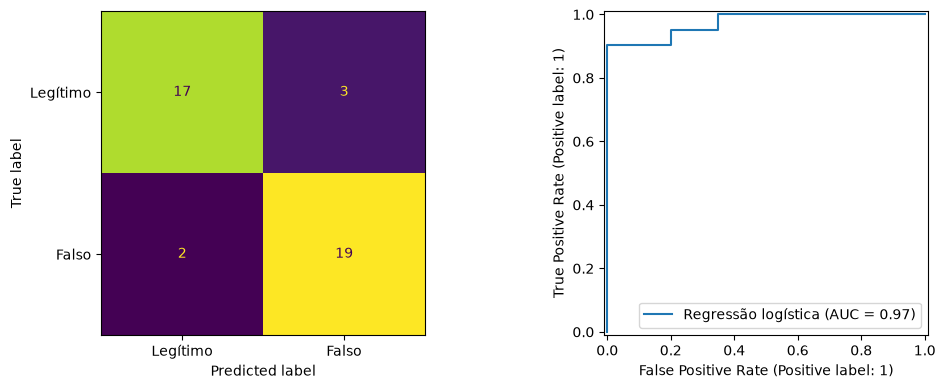

In [11]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay)

modelo = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=3000, random_state=SEMENTE))
modelo.fit(treino[COLUNAS_FEATURES], treino.rotulo)
y_teste = teste.rotulo.to_numpy()
pred = modelo.predict(teste[COLUNAS_FEATURES])
scores = modelo.predict_proba(teste[COLUNAS_FEATURES])[:, list(modelo.classes_).index(1)]
metricas = {
    "modelo": "regressao_logistica", "C": 1.0, "n_features": len(COLUNAS_FEATURES),
    "n_treino": len(treino), "n_teste": len(teste), "agrupamento": TIPO_GRUPO,
    "accuracy": accuracy_score(y_teste, pred),
    "balanced_accuracy": balanced_accuracy_score(y_teste, pred),
    "precision_falso": precision_score(y_teste, pred, zero_division=0),
    "recall_falso": recall_score(y_teste, pred, zero_division=0),
    "f1_falso": f1_score(y_teste, pred, zero_division=0),
    "roc_auc": roc_auc_score(y_teste, scores),
    "average_precision": average_precision_score(y_teste, scores),
}
(RESULTADOS_DIR / "metricas_teste.json").write_text(json.dumps(metricas, indent=2), encoding="utf-8")
pd.DataFrame({"sha256": teste.sha256, "rotulo_real": y_teste, "predicao": pred, "score_falso": scores}).to_csv(RESULTADOS_DIR / "predicoes_teste.csv", index=False)
config["classificador"] = {"nome": "regressao_logistica", "C": 1.0, "max_iter": 3000, "padronizacao": "ajustada somente no treino"}
(RESULTADOS_DIR / "configuracao.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
print(json.dumps(metricas, indent=2))
print(classification_report(y_teste, pred, target_names=["Legítimo", "Falso"], zero_division=0))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_teste, pred, display_labels=["Legítimo", "Falso"], ax=axes[0], colorbar=False)
RocCurveDisplay.from_predictions(y_teste, scores, ax=axes[1], name="Regressão logística")
fig.tight_layout()
fig.savefig(FIGURAS_DIR / "avaliacao-teste.png", dpi=160, bbox_inches="tight")
plt.show()


### Resultados
O modelo acertou 36 dos 41 áudios: **87,80% de acurácia**, **88,37% de F1 para áudio falso** e **0,9738 de ROC-AUC**. Foram 3 legítimos classificados como falsos e 2 falsos como legítimos.

O resultado vale para esta amostra pequena e não garante o mesmo desempenho em outras bases. Realizei a atividade localmente, com adaptação das etapas de Drive e Colab.


### Referências
- [Dataset Kaggle](https://www.kaggle.com/datasets/ulianazb/asvspoof-2024).
- [Librosa — extração de características](https://librosa.org/doc/0.11.0/feature.html).
